In [ ]:
from pathlib import Path
import sys

PROJECT_ROOT = Path(
    "/Users/hongmo/Desktop/Gradient Boosting"
)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import load_and_split_data
from src.early_stopping import train_xgboost_early_stopping
from sklearn.metrics import roc_auc_score
import matplotlib.pyplot as plt

In [6]:
import json

params_path = PROJECT_ROOT / "outputs" / "best_xgboost_params.json"

with open(params_path, "r") as f:
    best_params = json.load(f)

print("Loaded parameters:")
print(best_params)

Loaded parameters:
{'n_estimators': 500, 'max_depth': 4, 'learning_rate': 0.04876245464299488, 'min_child_weight': 8, 'subsample': 0.907837907296553, 'colsample_bytree': 0.9845802026575938, 'reg_alpha': 0.011054544831479282, 'reg_lambda': 4.665644370038743}


In [7]:
from src.early_stopping import train_xgboost_early_stopping

model, preprocessor = train_xgboost_early_stopping(
    X_train,
    y_train,
    params=best_params,
    early_stopping_rounds=30
)

print("Best iteration:", model.best_iteration)
print("Best Early-Stopping AUC:", model.best_score)

Best iteration: 684
Best Early-Stopping AUC: 0.7536193307759551


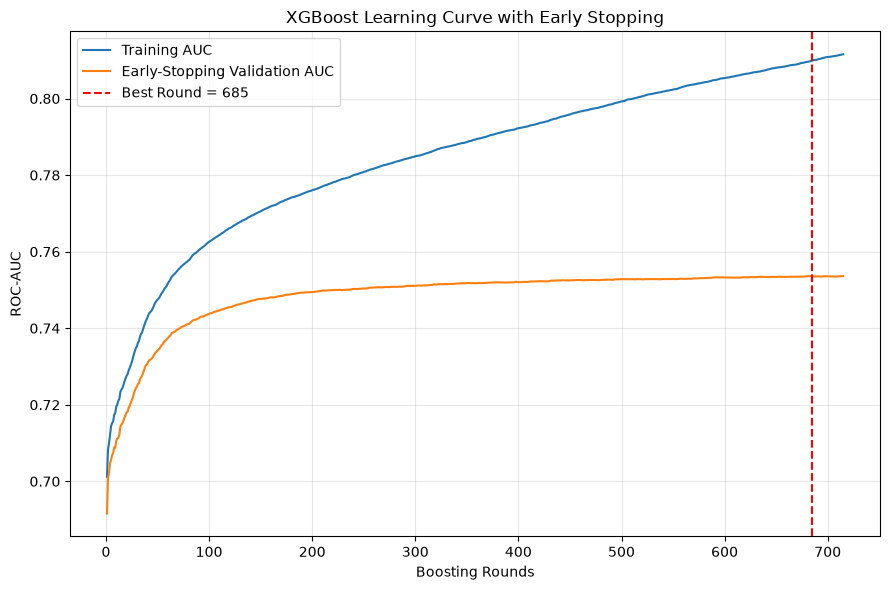

In [8]:
import matplotlib.pyplot as plt

# Retrieve evaluation history
results = model.evals_result()

train_auc = results["validation_0"]["auc"]
es_auc = results["validation_1"]["auc"]

rounds = range(1, len(train_auc) + 1)

plt.figure(figsize=(9, 6))

# Training AUC
plt.plot(
    rounds,
    train_auc,
    label="Training AUC"
)

# Early-stopping validation AUC
plt.plot(
    rounds,
    es_auc,
    label="Early-Stopping Validation AUC"
)

# Best iteration
plt.axvline(
    model.best_iteration + 1,
    color="red",
    linestyle="--",
    label=f"Best Round = {model.best_iteration + 1}"
)

plt.title("XGBoost Learning Curve with Early Stopping")
plt.xlabel("Boosting Rounds")
plt.ylabel("ROC-AUC")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [9]:
from sklearn.metrics import roc_auc_score

# Apply fitted preprocessing
X_val_processed = preprocessor.transform(X_val)

# Predict probabilities
y_val_prob = model.predict_proba(X_val_processed)[:, 1]

# Calculate ROC-AUC
val_auc = roc_auc_score(y_val, y_val_prob)

print(f"Early-Stopping Model Validation AUC: {val_auc:.4f}")

Early-Stopping Model Validation AUC: 0.7589


In [10]:
from src.preprocessing import build_preprocessor
from src.models import build_xgboost_pipeline

final_params = best_params.copy()

# best_iteration is zero-indexed
final_params["n_estimators"] = model.best_iteration + 1

final_preprocessor = build_preprocessor(
    X_train,
    scale_numeric=False
)

final_pipeline = build_xgboost_pipeline(
    final_preprocessor,
    params=final_params
)

final_pipeline.fit(X_train, y_train)

# Evaluate on the original validation set
final_val_prob = final_pipeline.predict_proba(X_val)[:, 1]

final_val_auc = roc_auc_score(y_val, final_val_prob)

print(f"Refitted Validation AUC: {final_val_auc:.4f}")

Refitted Validation AUC: 0.7605


In [11]:
from sklearn.metrics import roc_auc_score

# Apply the fitted preprocessor
X_val_processed = preprocessor.transform(X_val)

# Predict probabilities
y_val_prob = model.predict_proba(X_val_processed)[:, 1]

# Calculate validation AUC
val_auc = roc_auc_score(y_val, y_val_prob)

print(f"Early-Stopping Validation AUC: {val_auc:.4f}")

Early-Stopping Validation AUC: 0.7589


In [12]:
from src.preprocessing import build_preprocessor
from src.models import build_xgboost_pipeline
from sklearn.metrics import roc_auc_score

# Copy the regularized hyperparameters
final_params = best_params.copy()

# Use the best round selected by early stopping
final_params["n_estimators"] = model.best_iteration + 1

# Build a fresh preprocessor
final_preprocessor = build_preprocessor(
    X_train,
    scale_numeric=False
)

# Build XGBoost pipeline
final_pipeline = build_xgboost_pipeline(
    final_preprocessor,
    params=final_params
)

# Refit on the full training set
final_pipeline.fit(X_train, y_train)

# Evaluate on validation set
final_val_prob = final_pipeline.predict_proba(X_val)[:, 1]
final_val_auc = roc_auc_score(y_val, final_val_prob)

print(f"Refitted Validation AUC: {final_val_auc:.4f}")
print(f"Boosting Rounds: {final_params['n_estimators']}")

Refitted Validation AUC: 0.7605
Boosting Rounds: 685


In [13]:
import joblib

model_path = PROJECT_ROOT / "outputs" / "xgboost_refitted.joblib"
model_path.parent.mkdir(parents=True, exist_ok=True)

joblib.dump(final_pipeline, model_path)

print("Model saved:", model_path)

Model saved: /Users/hongmo/Desktop/Gradient Boosting/outputs/xgboost_refitted.joblib
